In [1]:
import pandas as pd

pd.set_option('display.max_columns', None)

In [2]:
df = pd.read_csv('../Resources/Revised Final Dataset.csv')
df['Month_Year'] = pd.to_datetime(df['Month_Year'], errors='coerce')
df.head()

,Sector,Fruits,Vegetables,Spices,Fuel and light,Health,Month_Year
0,Rural,103.9,101.9,103.1,105.5,104.0,2013-01-01
1,Urban,102.3,102.9,101.8,105.4,104.1,2013-01-01
2,Rural+Urban,103.2,102.2,102.7,105.5,104.0,2013-01-01
3,Rural,104.0,102.4,103.1,106.2,104.4,2013-02-01
4,Urban,103.1,104.9,102.3,105.7,104.7,2013-02-01


In [3]:
df.set_index('Month_Year', inplace=True)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 453 entries, 2013-01-01 to 2025-07-01
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Sector          453 non-null    object 
 1   Fruits          453 non-null    float64
 2   Vegetables      453 non-null    float64
 3   Spices          453 non-null    float64
 4   Fuel and light  453 non-null    float64
 5   Health          453 non-null    float64
dtypes: float64(5), object(1)
memory usage: 24.8+ KB


In [5]:
col_order = ['Sector', 'Fruits', 'Vegetables', 'Spices', 'Fuel and light', 'Health']
df = df[col_order]

In [6]:
df.head()

,Sector,Fruits,Vegetables,Spices,Fuel and light,Health
Month_Year,,,,,,
2013-01-01,Rural,103.9,101.9,103.1,105.5,104.0
2013-01-01,Urban,102.3,102.9,101.8,105.4,104.1
2013-01-01,Rural+Urban,103.2,102.2,102.7,105.5,104.0
2013-02-01,Rural,104.0,102.4,103.1,106.2,104.4
2013-02-01,Urban,103.1,104.9,102.3,105.7,104.7


In [7]:
df = df[df['Sector']=='Rural+Urban'].copy()
df = df.asfreq('MS')

In [8]:
df.index.min(), df.index.max()

(Timestamp('2013-01-01 00:00:00'), Timestamp('2025-07-01 00:00:00'))

In [9]:
pd.date_range(start=df.index.min(), end=df.index.max(), freq='MS')

DatetimeIndex(['2013-01-01', '2013-02-01', '2013-03-01', '2013-04-01',
               '2013-05-01', '2013-06-01', '2013-07-01', '2013-08-01',
               '2013-09-01', '2013-10-01',
               ...
               '2024-10-01', '2024-11-01', '2024-12-01', '2025-01-01',
               '2025-02-01', '2025-03-01', '2025-04-01', '2025-05-01',
               '2025-06-01', '2025-07-01'],
              dtype='datetime64[ns]', length=151, freq='MS')

In [10]:
full_range = pd.date_range(start=df.index.min(), end=df.index.max(), freq='MS')

In [11]:
df.index

DatetimeIndex(['2013-01-01', '2013-02-01', '2013-03-01', '2013-04-01',
               '2013-05-01', '2013-06-01', '2013-07-01', '2013-08-01',
               '2013-09-01', '2013-10-01',
               ...
               '2024-10-01', '2024-11-01', '2024-12-01', '2025-01-01',
               '2025-02-01', '2025-03-01', '2025-04-01', '2025-05-01',
               '2025-06-01', '2025-07-01'],
              dtype='datetime64[ns]', name='Month_Year', length=151, freq='MS')

In [12]:
df.isna().sum()

Sector            0
Fruits            0
Vegetables        0
Spices            0
Fuel and light    0
Health            0
dtype: int64

In [13]:
df[df['Health'].isna()]['Health']
df['Health'].interpolate().loc['2019-03-01':'2019-05-01']

Month_Year
2019-03-01    146.2
2019-04-01    146.6
2019-05-01    146.9
Freq: MS, Name: Health, dtype: float64

In [14]:
df['Health'] = df['Health'].interpolate()
df['Health'].isna().sum()

0

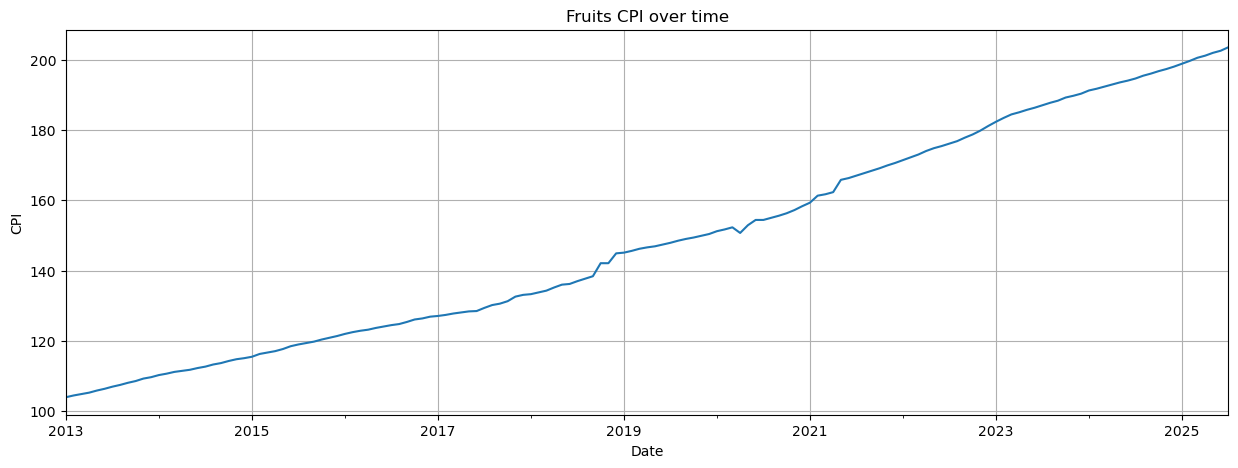

In [15]:
import matplotlib.pyplot as plt
plt.figure(figsize=(15,5))
df['Health'].plot()
plt.title('Fruits CPI over time')
plt.xlabel('Date')
plt.ylabel('CPI')
plt.grid(True)
plt.show()

In [16]:
from statsmodels.tsa.seasonal import STL
stl = STL(df['Health'], period=12)
result = stl.fit()

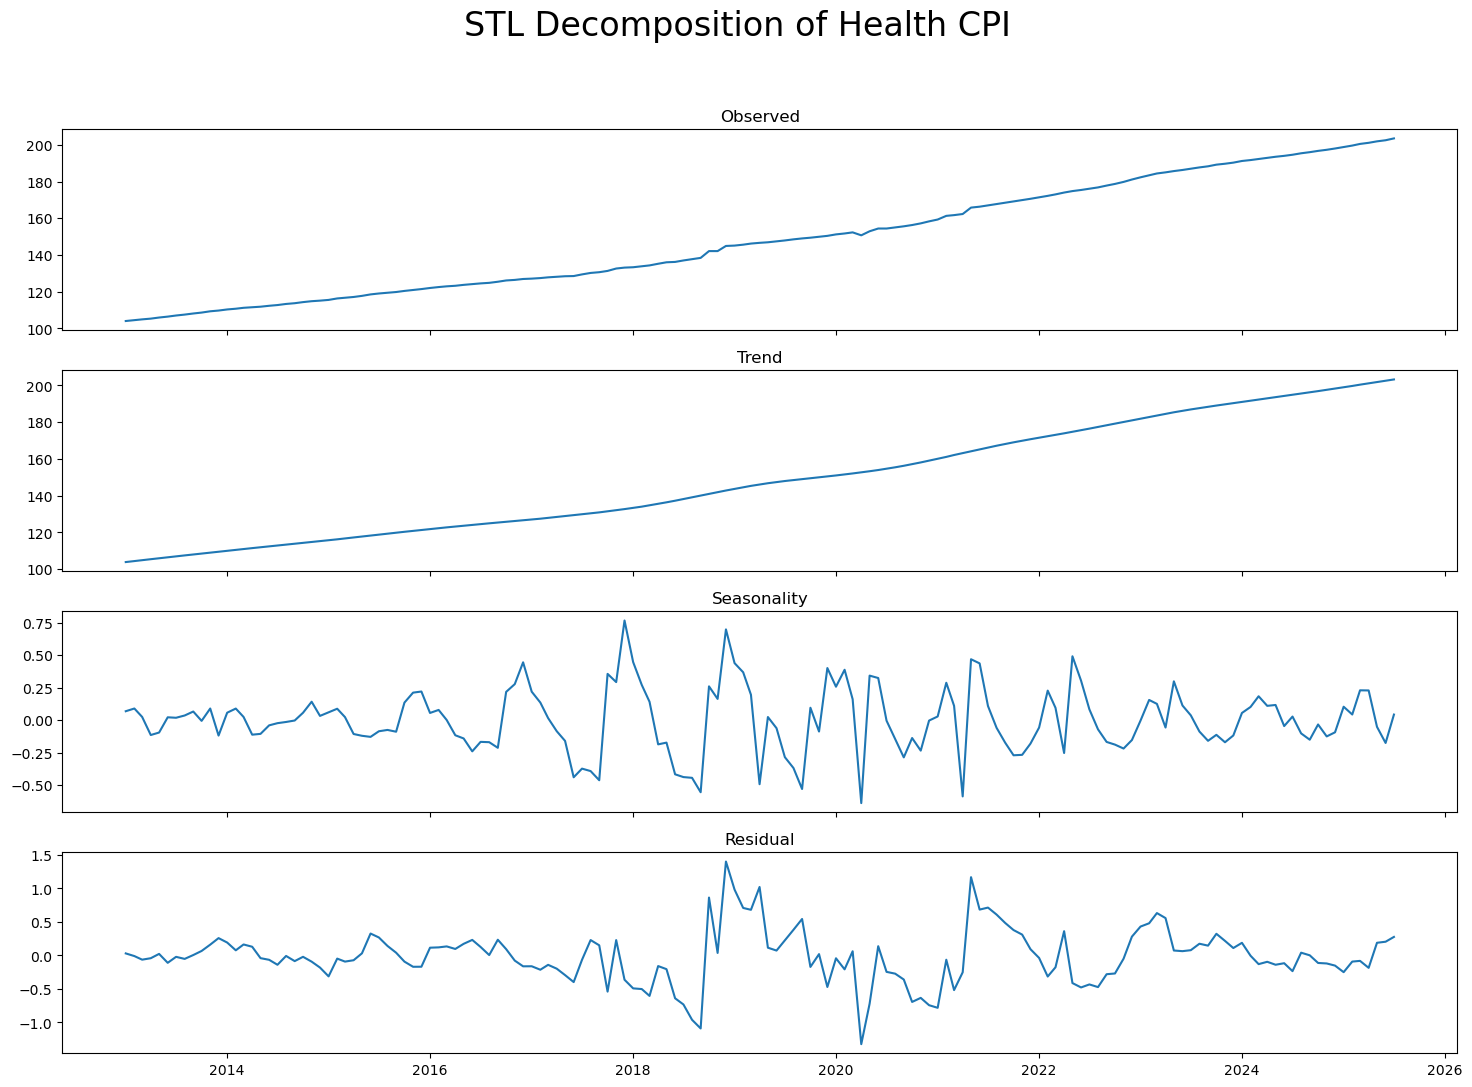

In [17]:
fig, axs = plt.subplots(4, 1, figsize=(18,12), sharex=True)

axs[0].plot(df.index, df['Health'], label='Observed')
axs[0].set_title('Observed')

axs[1].plot(df.index, result.trend, label='Trend')
axs[1].set_title('Trend')

axs[2].plot(df.index, result.seasonal, label='Seasonality')
axs[2].set_title('Seasonality')

axs[3].plot(df.index, result.resid, label='Residual')
axs[3].set_title('Residual')

plt.suptitle('STL Decomposition of Health CPI', fontsize=24)
plt.show()

In [18]:
from statsmodels.tsa.stattools import adfuller

adf_result = adfuller(df['Health'])
adf_result

(1.9061681096274572,
 0.9985378781835899,
 3,
 147,
 {'1%': -3.4756368462466662,
  '5%': -2.8814104466172608,
  '10%': -2.5773652982553568},
 215.6818437422452)

In [19]:
adf_result[0]

1.9061681096274572

In [20]:
adf_result[1]

0.9985378781835899

In [21]:
#cannot reject null hypothesis as 0.92428 > 0.05

In [22]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

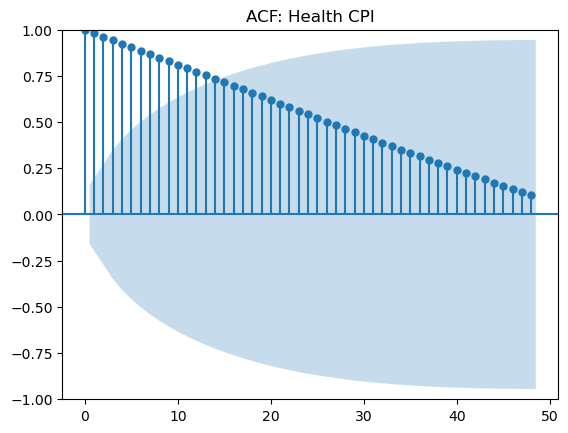

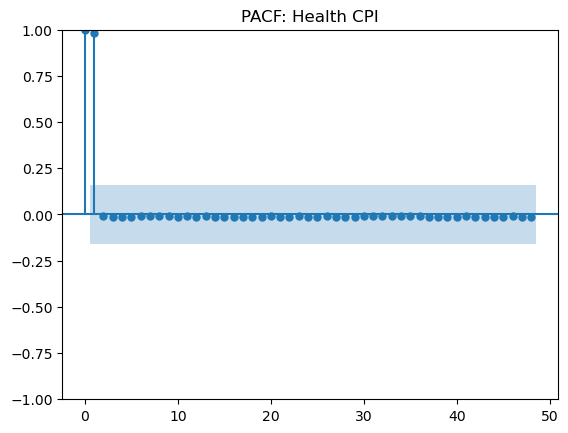

In [23]:
plot_acf(df['Health'], lags=48)
plt.title('ACF: Health CPI')
plt.show()

plot_pacf(df['Health'], lags=48)
plt.title('PACF: Health CPI')
plt.show()

In [24]:
# AR from PACF: sharp drop is from lag 1
# MA from ACF: lags 1 to 8 are significant 

In [25]:
test_size = 12 
train = df['Health'].iloc[0:-test_size]
test = df['Health'].iloc[-test_size:]

In [26]:
from statsmodels.tsa.arima.model import ARIMA

In [27]:
model = ARIMA(train, order=(0,2,1), seasonal_order=(0,1,1,12))
results = model.fit()

results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                    SARIMAX Results                                     
========================================================================================
Dep. Variable:                           Health   No. Observations:                  139
Model:             ARIMA(0, 2, 1)x(0, 1, 1, 12)   Log Likelihood                -114.448
Date:                          Sun, 22 Nov 2026   AIC                            234.896
Time:                                  15:23:53   BIC                            243.381
Sample:                              01-01-2013   HQIC                           238.343
                                   - 07-01-2024                                         
Covariance Type:                            opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.9968      0.518     -1.925      0.054      -2.011       0.018
ma.S.L12      -0.9947      2.444     -0.407      0.684      -5.785       3.796
sigma2         0.2750      0.647      0.425      0.671      -0.993       1.543
===================================================================================
Ljung-Box (L1) (Q):                   2.26   Jarque-Bera (JB):               699.62
Prob(Q):                              0.13   Prob(JB):                         0.00
Heteroskedasticity (H):               9.86   Skew:                             2.10
Prob(H) (two-sided):                  0.00   Kurtosis:                        13.81
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

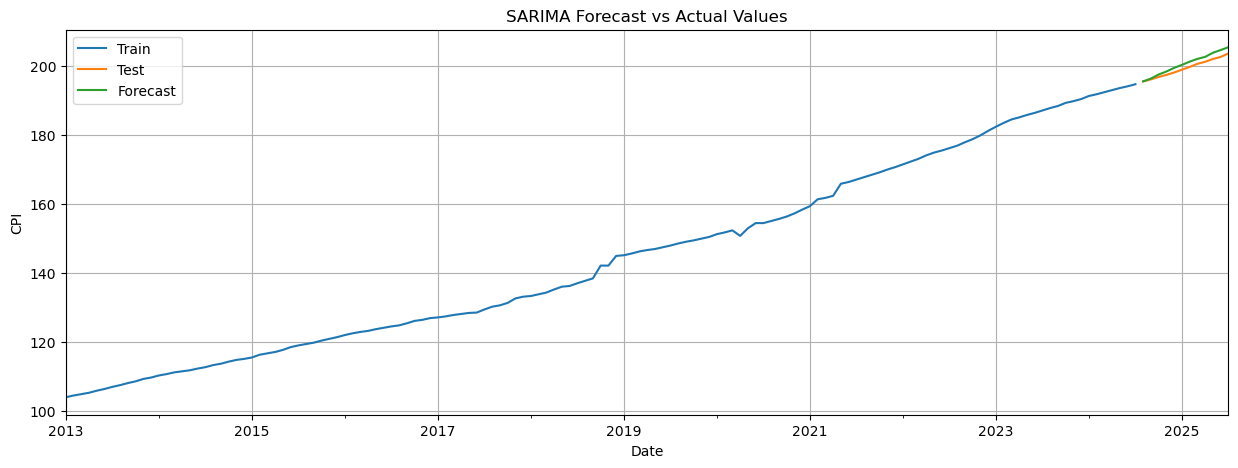

In [28]:
sarima_forecast = results.forecast(steps=test_size)

plt.figure(figsize=(15, 5))

train.plot(label='Train')
test.plot(label='Test')

sarima_forecast.index = test.index
sarima_forecast.plot(label='Forecast')

plt.title('SARIMA Forecast vs Actual Values')
plt.xlabel('Date')
plt.ylabel('CPI')
plt.legend()
plt.grid(True)

plt.show()

In [29]:
import numpy as np
from sklearn.metrics import mean_squared_error

rmse = mean_squared_error(test, sarima_forecast)
tmse = np.sqrt(rmse)
tmse

1.3603362891688024

In [30]:
s = 12

p_values = [0, 1, 2]
d_values = [1]
q_values = [0, 1, 2]

P_values = [0, 1, 2]
D_values = [1]
Q_values = [0, 1, 2]

In [31]:
param_grid = [((p, d, q), (P, D, Q, s))
 for p in p_values
 for d in d_values
 for q in q_values
 for P in P_values
 for D in D_values
 for Q in Q_values]

len(param_grid)

81

In [32]:
from sklearn.model_selection import TimeSeriesSplit

In [33]:
X = df['Health']
tscv = TimeSeriesSplit(n_splits=3, test_size=12)
tscv

TimeSeriesSplit(gap=0, max_train_size=None, n_splits=3, test_size=12)

In [34]:
len(list(tscv.split(X)))

3

In [35]:
list(tscv.split(X))

[(array([  0,   1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,
          13,  14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,
          26,  27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,
          39,  40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,  51,
          52,  53,  54,  55,  56,  57,  58,  59,  60,  61,  62,  63,  64,
          65,  66,  67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,
          78,  79,  80,  81,  82,  83,  84,  85,  86,  87,  88,  89,  90,
          91,  92,  93,  94,  95,  96,  97,  98,  99, 100, 101, 102, 103,
         104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114]),
  array([115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126])),
 (array([  0,   1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,
          13,  14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,
          26,  27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,
          39,  40,  41,  42,  43,  44,  45,  46,

In [36]:
from tqdm import tqdm

metrics = []

for order, seasonal_order in tqdm(param_grid):
    split_rmse = []

    for train_idx, test_idx in tscv.split(X):
        X_train = X.iloc[train_idx]
        X_test = X.iloc[test_idx]

        model = ARIMA(X_train, order=order, seasonal_order=seasonal_order)
        results = model.fit()

        X_pred = results.forecast(steps=len(X_test))
        rmse = np.sqrt(mean_squared_error(X_test, X_pred))
        split_rmse.append(rmse)

    mean_rmse = np.mean(split_rmse)
    std_rmse = np.std(split_rmse)

    metrics.append(
        {'order': order,
         'seasonal_order': seasonal_order,
         'rmse_mean': mean_rmse,
         'rmse_std': std_rmse}
    )

  0%|          | 0/81 [00:00<?, ?it/s]

/opt/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


/opt/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


 32%|███▏      | 26/81 [01:05<02:18,  2.52s/it]

/opt/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


/opt/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


... (26 outputs left out)

/opt/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


/opt/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


/opt/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


100%|██████████| 81/81 [04:48<00:00,  3.56s/it]

In [37]:
metrics_df = pd.DataFrame(metrics)
metrics_df

,order,seasonal_order,rmse_mean,rmse_std
0,"(0, 1, 0)","(0, 1, 0, 12)",1.480324,0.707520
1,"(0, 1, 0)","(0, 1, 1, 12)",1.003740,0.703911
2,"(0, 1, 0)","(0, 1, 2, 12)",1.094435,0.849178
3,"(0, 1, 0)","(1, 1, 0, 12)",1.074306,0.489452
4,"(0, 1, 0)","(1, 1, 1, 12)",1.070730,0.840157
...,...,...,...,...
76,"(2, 1, 2)","(1, 1, 1, 12)",1.107971,0.846388
77,"(2, 1, 2)","(1, 1, 2, 12)",1.231134,0.885607
78,"(2, 1, 2)","(2, 1, 0, 12)",1.388701,0.867357
79,"(2, 1, 2)","(2, 1, 1, 12)",1.238270,0.876202


In [38]:
metrics_df.sort_values(by='rmse_mean', ascending=True)

,order,seasonal_order,rmse_mean,rmse_std
46,"(1, 1, 2)","(0, 1, 1, 12)",0.959852,0.779628
73,"(2, 1, 2)","(0, 1, 1, 12)",0.972071,0.809489
37,"(1, 1, 1)","(0, 1, 1, 12)",0.993943,0.681603
28,"(1, 1, 0)","(0, 1, 1, 12)",0.996207,0.684077
10,"(0, 1, 1)","(0, 1, 1, 12)",0.997339,0.687977
...,...,...,...,...
54,"(2, 1, 0)","(0, 1, 0, 12)",1.481772,0.698890
18,"(0, 1, 2)","(0, 1, 0, 12)",1.530915,0.709166
63,"(2, 1, 1)","(0, 1, 0, 12)",1.781717,0.733095
72,"(2, 1, 2)","(0, 1, 0, 12)",1.818017,0.884712


In [39]:
model = ARIMA(train, order=(1,1,2), seasonal_order=(0,1,1,12))
results = model.fit()

results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                     SARIMAX Results                                      
==========================================================================================
Dep. Variable:                             Health   No. Observations:                  139
Model:             ARIMA(1, 1, 2)x(0, 1, [1], 12)   Log Likelihood                -109.330
Date:                            Sun, 22 Nov 2026   AIC                            228.659
Time:                                    15:28:42   BIC                            242.841
Sample:                                01-01-2013   HQIC                           234.421
                                     - 07-01-2024                                         
Covariance Type:                              opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.7596      0.243      3.129      0.002       0.284       1.235
ma.L1         -0.8762      0.256     -3.424      0.001      -1.378      -0.375
ma.L2          0.2717      0.064      4.216      0.000       0.145       0.398
ma.S.L12      -0.9979      7.312     -0.136      0.891     -15.330      13.334
sigma2         0.2633      1.914      0.138      0.891      -3.487       4.014
===================================================================================
Ljung-Box (L1) (Q):                   0.04   Jarque-Bera (JB):               658.88
Prob(Q):                              0.84   Prob(JB):                         0.00
Heteroskedasticity (H):              10.74   Skew:                             2.03
Prob(H) (two-sided):                  0.00   Kurtosis:                        13.44
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

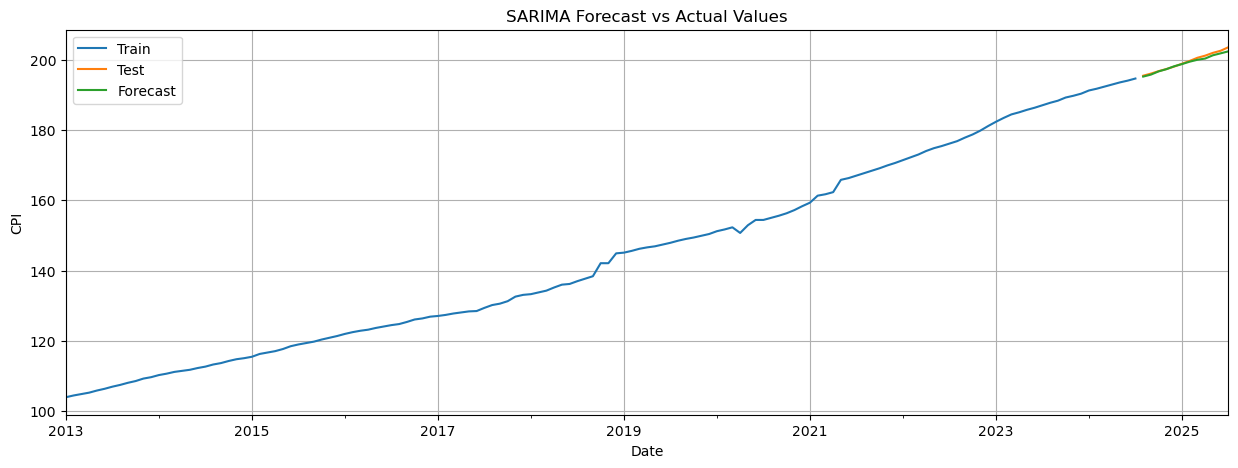

In [40]:
sarima_forecast = results.forecast(steps=test_size)

plt.figure(figsize=(15, 5))

train.plot(label='Train')
test.plot(label='Test')

sarima_forecast.index = test.index
sarima_forecast.plot(label='Forecast')

plt.title('SARIMA Forecast vs Actual Values')
plt.xlabel('Date')
plt.ylabel('CPI')
plt.legend()
plt.grid(True)

plt.show()

In [41]:
import numpy as np
from sklearn.metrics import mean_squared_error

rmse = mean_squared_error(test, sarima_forecast)
tmse = np.sqrt(rmse)
tmse

0.5478505473601114

In [42]:
import joblib
joblib.dump(results, 'Health-Total.pkl')

['Health-Total.pkl']